# Employee Attrition Prediction — Group 5_C9 (simple version)

Which employees are likely to leave, and what is linked to leaving?
Data: IBM HR Analytics Employee Attrition (fictional, 1,470 employees, 16% left).
Full context, team and how to run: see the repository
[README](https://github.com/Trumpibeabuchi/techcrush-c9-group5-attrition#readme).

**Hypotheses (written before the analysis):**
H1 overtime · H2 pay · H3 tenure/age · H4 satisfaction · H5 travel · H6 job role ·
H7 gender/education (control)

**Note:** units are not documented, and the data is fictional, so results are
compared in relative terms.

## 1. Setup

Libraries used throughout the notebook, and a `figures/` folder for the charts used in the report and slides.

In [1]:
# Import libraries for data manipulation

import pandas as pd
import numpy as np

# Import libraries for data visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Import statistical tests used in the EDA

from scipy.stats import chi2_contingency, mannwhitneyu

from pathlib import Path

# Set visualization style

sns.set_theme(style="whitegrid")

# Display all columns

pd.set_option("display.max_columns", None)

# Folder for exported charts (used in the report and slides).
# Saved to the repository's figures/ folder, whether Jupyter starts in the
# repository root or in notebooks/. In Colab they go to /content/figures
# (download them from the Files panel).

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

print("All libraries imported successfully.")

All libraries imported successfully.


## 2. Data Loading

The CSV is stored in the `data/` folder of this repository and read from there.

In [2]:
# Load the dataset directly from the team GitHub repository,
# so 'Run all' works without a manual upload.

DATA_URL = (
    "https://raw.githubusercontent.com/Trumpibeabuchi/techcrush-c9-group5-attrition/"
    "main/data/WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

df = pd.read_csv(DATA_URL)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
# Dataset dimensions

n_rows, n_cols = df.shape

print(f"The dataset has {n_rows:,} rows (employees) and {n_cols} columns.")

The dataset has 1,470 rows (employees) and 35 columns.


**Finding:** each row is one employee (1,470 in total), described by 35 columns.
The target is `Attrition` (Yes = the employee left, No = stayed).

## 3. Data Quality Assessment

Before exploring patterns, we check that the data can be trusted: are values missing or
duplicated, do the numbers and categories make sense, and does every column carry useful
information? The section ends with the cleaning decisions.

### 3.1 Data types and missing values

`df.info()` shows each column's type and how many values are filled in.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [5]:
# Total number of missing values across the whole dataset

print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


**Finding:** no missing values: every column has 1,470 non-null entries.
Types are as expected: 26 numeric columns and 9 text (categorical) columns.

### 3.2 Duplicate records

Every row has a unique `EmployeeNumber`, so comparing whole rows could never find a duplicate.
We therefore check for duplicates **ignoring the ID**: two rows identical in everything else
would be the same employee entered twice.

In [6]:
# Is the employee ID unique?

print("EmployeeNumber is unique:", df["EmployeeNumber"].is_unique)

# Duplicates when the ID is ignored

duplicates = df.drop(columns="EmployeeNumber").duplicated().sum()

print("Duplicate records (ignoring the ID):", duplicates)

EmployeeNumber is unique: True
Duplicate records (ignoring the ID): 0


**Finding:** no duplicate employees, so no rows need to be removed.

### 3.3 Value ranges and categories

We check that numbers fall in sensible ranges and that categories contain no typos or
placeholder values such as "?" or "Unknown" (missing values in disguise, which
`isnull()` would not catch).

In [7]:
# Summary of numerical columns

df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [8]:
# Summary of categorical columns

df.describe(include="object")

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


In [9]:
# List the categories of each text column, to spot typos or placeholders

for column in df.select_dtypes(include="object").columns:
    print(f"{column}: {sorted(df[column].unique())}")

Attrition: ['No', 'Yes']
BusinessTravel: ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
Department: ['Human Resources', 'Research & Development', 'Sales']
EducationField: ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']
Gender: ['Female', 'Male']
JobRole: ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
MaritalStatus: ['Divorced', 'Married', 'Single']
Over18: ['Y']
OverTime: ['No', 'Yes']


In [10]:
# Logical consistency: years at the company cannot exceed total working years,
# and years in the current role cannot exceed years at the company

print("YearsAtCompany > TotalWorkingYears:",
      (df["YearsAtCompany"] > df["TotalWorkingYears"]).sum())

print("YearsInCurrentRole > YearsAtCompany:",
      (df["YearsInCurrentRole"] > df["YearsAtCompany"]).sum())

YearsAtCompany > TotalWorkingYears: 0
YearsInCurrentRole > YearsAtCompany: 0


**Finding:**
1. All values are plausible.
2. Age runs from 18 to 60, years at the company
from 0 to 40, and the satisfaction scores from 1 to 4.
3. Every category is a clean label,
with no typos or placeholder values, and the year columns are consistent with each other.

**NOTE:** Units are not documented: income has no currency and distance from home has no unit.
Because the data is also fictional, results are compared in relative terms
(for example "leavers earn X% less"), never in a specified currency.

### 3.4 Constant and identifier columns

A column with the same value for every employee cannot help to tell leavers from stayers.

In [11]:
# Columns with only one unique value

constant_columns = [
    column for column in df.columns
    if df[column].nunique() == 1
]

print("Constant columns:", constant_columns)

Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


**Finding:** `EmployeeCount` (always 1), `Over18` (always "Y") and `StandardHours`
(always 80) are constant.

### 3.5 Which column measures pay?

The dataset has four pay-like columns: `MonthlyIncome`, `MonthlyRate`, `DailyRate` and
`HourlyRate`. If they all measured pay, they would rise and fall together, and they
would rise with seniority. We compare them with each other and with two seniority
columns, `JobLevel` and `TotalWorkingYears`.

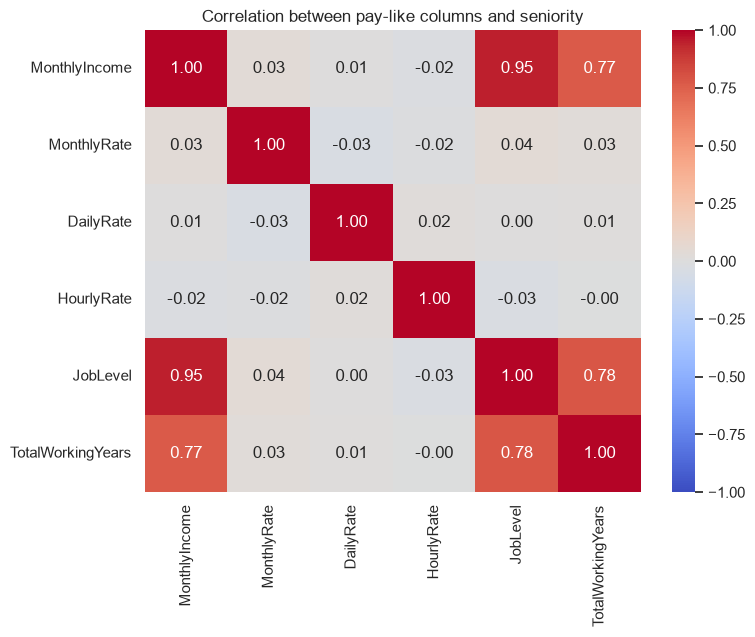

In [12]:
pay_columns = [
    "MonthlyIncome", "MonthlyRate", "DailyRate", "HourlyRate",
    "JobLevel", "TotalWorkingYears"
]

pay_corr = df[pay_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    pay_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation between pay-like columns and seniority")

plt.savefig(
    f"{FIG_DIR}/pay_columns_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Finding:** `MonthlyIncome` behaves like real pay. It rises strongly with job level
(correlation 0.95) and total working years (0.77). The three "Rate" columns are not
related to income, to each other, or to seniority (all correlations between −0.03 and
0.04), so their meaning is unclear. **EDA will therefore use `MonthlyIncome`
only.**

### 3.6 Summary and cleaning decisions

| Check | Result | Action |
|---|---|---|
| Missing values | None | None |
| Duplicates | None (checked ignoring the ID) | None |
| Value ranges and categories | Plausible and clean; units not documented | Compare results in relative terms |
| Constant columns | `EmployeeCount`, `Over18`, `StandardHours` | Drop |
| Identifier | `EmployeeNumber` | Drop |
| Pay columns | Only `MonthlyIncome` behaves like pay | Use `MonthlyIncome` for EDA |

The cleaned data is stored as `df_clean` and used in the rest of the notebook.

In [13]:
# Drop the constant columns and the identifier

columns_to_drop = constant_columns + ["EmployeeNumber"]

df_clean = df.drop(columns=columns_to_drop)

print("Dropped:", columns_to_drop)
print(f"Cleaned data: {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns.")

Dropped: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Cleaned data: 1,470 rows and 31 columns.


## 4. Exploratory Data Analysis

**Question:** what is linked to employees leaving?

We check each of our ideas (hypotheses H1–H7) the same way: we compare the **% of people
who left** in each group with the average of **16.1%**. A group well above the average
is at higher risk.

We also check that each difference is **real and not just chance** (with a chi-square
test). These are links, not proof of cause.

### 4.1 How many employees left?

In [14]:
attrition_summary = pd.DataFrame({
    "Employees": df_clean["Attrition"].value_counts(),
    "%": (df_clean["Attrition"].value_counts(normalize=True) * 100).round(1)
})

attrition_summary

,Employees,%
Attrition,,
No,1233,83.9
Yes,237,16.1


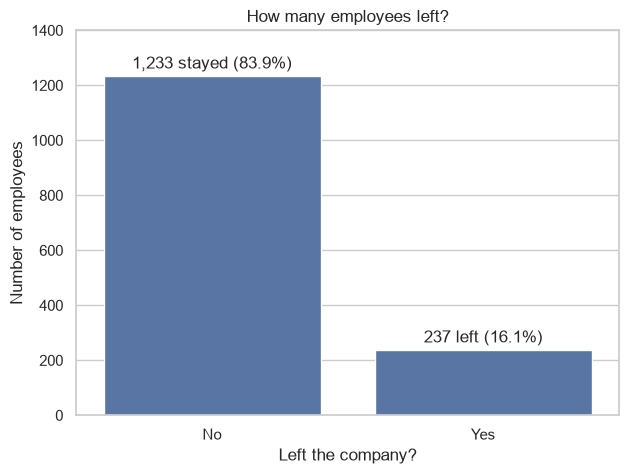

In [15]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df_clean, x="Attrition", order=["No", "Yes"])

ax.bar_label(ax.containers[0], labels=["1,233 stayed (83.9%)", "237 left (16.1%)"], padding=3)

ax.set_ylim(0, 1400)

plt.title("How many employees left?")
plt.xlabel("Left the company?")
plt.ylabel("Number of employees")

plt.savefig(f"{FIG_DIR}/simple_attrition.png", dpi=300, bbox_inches="tight")
plt.show()

**What we found:** about **1 in 6** employees left (237 of 1,470, or 16.1%).
This is the average we compare every group with.

### Two small tools used in every section

`rate_chart` draws the % who left in each group, with the 16.1% average as a dashed line.
`is_it_chance` says in plain words whether a difference is real or could be chance.

In [16]:
eda_df = df_clean.copy()  # copy for the EDA, so extra columns stay out of df_clean

overall_rate = (eda_df["Attrition"] == "Yes").mean() * 100


def rate_chart(column, title, filename=None, order=None, horizontal=False):
    """Bar chart of the % of employees who left in each group."""
    rates = (
        eda_df.groupby(column, observed=True)["Attrition"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .round(1)
    )
    if order is not None:
        rates = rates.reindex(order)

    plt.figure(figsize=(9, 6) if horizontal else (8, 5))
    if horizontal:
        ax = sns.barplot(x=rates.values, y=rates.index.astype(str), color="steelblue")
        ax.axvline(overall_rate, ls="--", color="grey")
        ax.set_xlim(0, rates.max() * 1.2)
        ax.set_xlabel("% who left")
        ax.set_ylabel("")
    else:
        ax = sns.barplot(x=rates.index.astype(str), y=rates.values, color="steelblue")
        ax.axhline(overall_rate, ls="--", color="grey")
        ax.set_ylim(0, rates.max() * 1.2)
        ax.set_ylabel("% who left")
        ax.set_xlabel("")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
    ax.set_title(f"{title}\n(dashed line = average {overall_rate:.1f}%)")
    if filename:
        plt.savefig(f"{FIG_DIR}/{filename}", dpi=300, bbox_inches="tight")
    plt.show()


def is_it_chance(column):
    """Chi-square test, explained in plain words."""
    p = chi2_contingency(pd.crosstab(eda_df[column], eda_df["Attrition"]))[1]
    if p < 0.05:
        print(f"{column}: real difference, very unlikely to be chance (p = {p:.2g})")
    else:
        print(f"{column}: no real difference, could easily be chance (p = {p:.2g})")

### 4.2 H1: Do people who work overtime leave more?

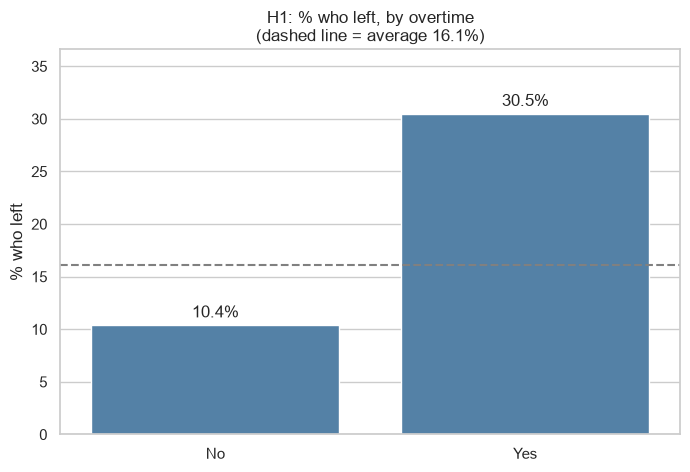

OverTime: real difference, very unlikely to be chance (p = 8.2e-21)


In [17]:
rate_chart(
    "OverTime",
    title="H1: % who left, by overtime",
    filename="simple_h1_overtime.png",
    order=['No', 'Yes']
)

is_it_chance("OverTime")

**Supported.** About **3 in 10** overtime workers left (30.5%), compared with
**1 in 10** of those who don't work overtime (10.4%), about **3 times more**.

**For HR:** keep an eye on teams with regular overtime and manage their workload.

### 4.3 H2: Do lower-paid people leave more?

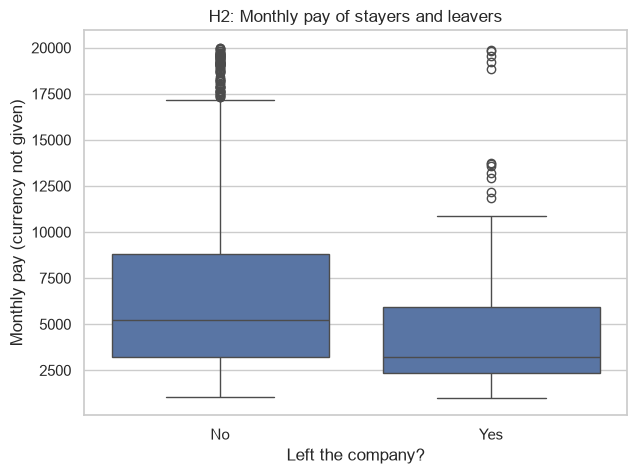

Leavers' typical (median) pay is 38% lower than stayers'.


In [18]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=eda_df, x="Attrition", y="MonthlyIncome", order=["No", "Yes"])

plt.title("H2: Monthly pay of stayers and leavers")
plt.xlabel("Left the company?")
plt.ylabel("Monthly pay (currency not given)")

plt.savefig(f"{FIG_DIR}/simple_h2_pay.png", dpi=300, bbox_inches="tight")
plt.show()

median_stayed = eda_df.loc[eda_df["Attrition"] == "No", "MonthlyIncome"].median()
median_left = eda_df.loc[eda_df["Attrition"] == "Yes", "MonthlyIncome"].median()

print(f"Leavers' typical (median) pay is {(1 - median_left / median_stayed) * 100:.0f}% lower than stayers'.")

But pay goes up with job level, so maybe leavers simply have more junior jobs.
We check the % who left at each job level, then compare pay **at the same level**.

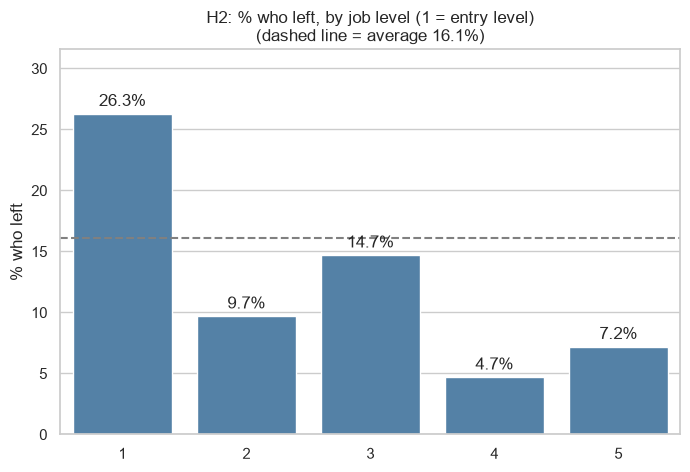

JobLevel: real difference, very unlikely to be chance (p = 6.6e-15)


In [19]:
rate_chart(
    "JobLevel",
    title="H2: % who left, by job level (1 = entry level)",
    filename="simple_h2_joblevel.png"
)

is_it_chance("JobLevel")

In [20]:
# Typical pay of stayers and leavers at the same job level

pay = (
    eda_df.groupby(["JobLevel", "Attrition"])["MonthlyIncome"]
    .median()
    .unstack()
)

pay["Leavers vs stayers (%)"] = ((pay["Yes"] / pay["No"] - 1) * 100).round(0)

pay.columns = ["Stayers' pay", "Leavers' pay", "Leavers vs stayers (%)"]

pay

,Stayers' pay,Leavers' pay,Leavers vs stayers (%)
JobLevel,,,
1,2719.0,2437.0,-10.0
2,5334.5,5346.0,0.0
3,9982.5,9887.0,-1.0
4,16307.0,13194.0,-19.0
5,19199.5,19545.0,2.0


**Partly supported.** Leavers earn less overall (typical pay 38% lower), but
mainly because many of them are **entry-level** staff: level 1 has the most leavers
(26.3%) and the lowest pay. **At the same job level, leavers and stayers earn about the
same**, except at entry level, where leavers earn about 10% less. (Level 4 looks
different, but it has only 5 leavers, too few to trust.)

**For HR:** pay rises for everyone are not the answer. Look at pay and promotion for
entry-level staff.

### 4.4 H3: Do new and young employees leave more?

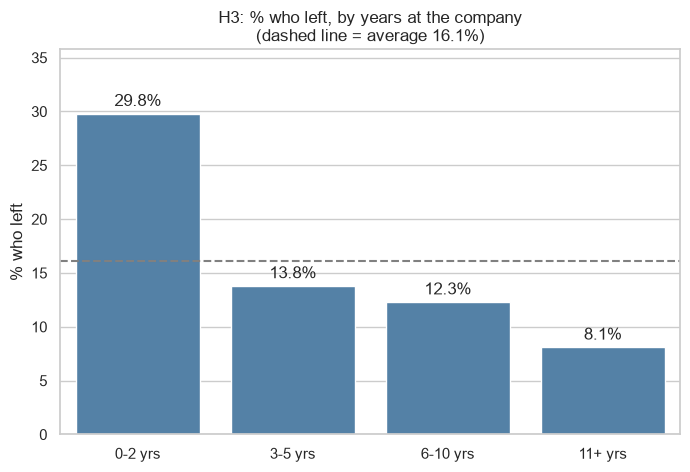

Years at company: real difference, very unlikely to be chance (p = 3.6e-14)


In [21]:
eda_df["Years at company"] = pd.cut(
    eda_df["YearsAtCompany"],
    bins=[-1, 2, 5, 10, 40],
    labels=["0-2 yrs", "3-5 yrs", "6-10 yrs", "11+ yrs"]
)

rate_chart("Years at company", title="H3: % who left, by years at the company", filename="simple_h3_tenure.png")

is_it_chance("Years at company")

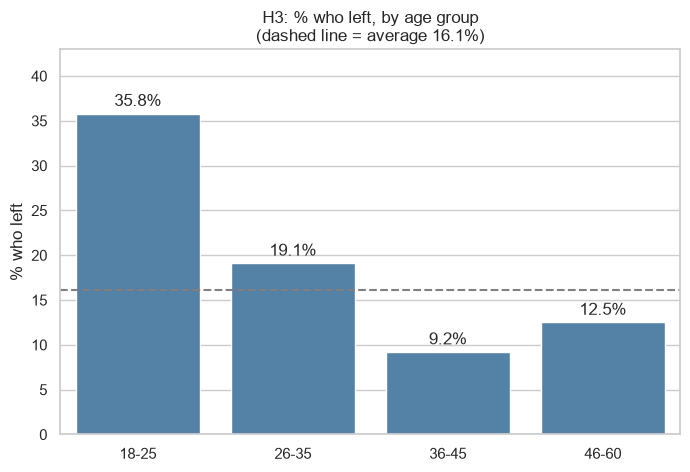

Age group: real difference, very unlikely to be chance (p = 1.2e-12)


In [22]:
eda_df["Age group"] = pd.cut(
    eda_df["Age"],
    bins=[17, 25, 35, 45, 60],
    labels=["18-25", "26-35", "36-45", "46-60"]
)

rate_chart("Age group", title="H3: % who left, by age group", filename="simple_h3_age.png")

is_it_chance("Age group")

**Supported.** About **3 in 10** people leave within their **first 2 years**
(29.8%), compared with fewer than 1 in 10 after 11+ years (8.1%). The youngest group
(**18–25**) leaves the most: 35.8%.

**For HR:** the first 2 years matter most: good onboarding, mentoring and early career
talks.

### 4.5 H4: Do unhappy employees leave more?

Each score goes from 1 (low) to 4 (high).

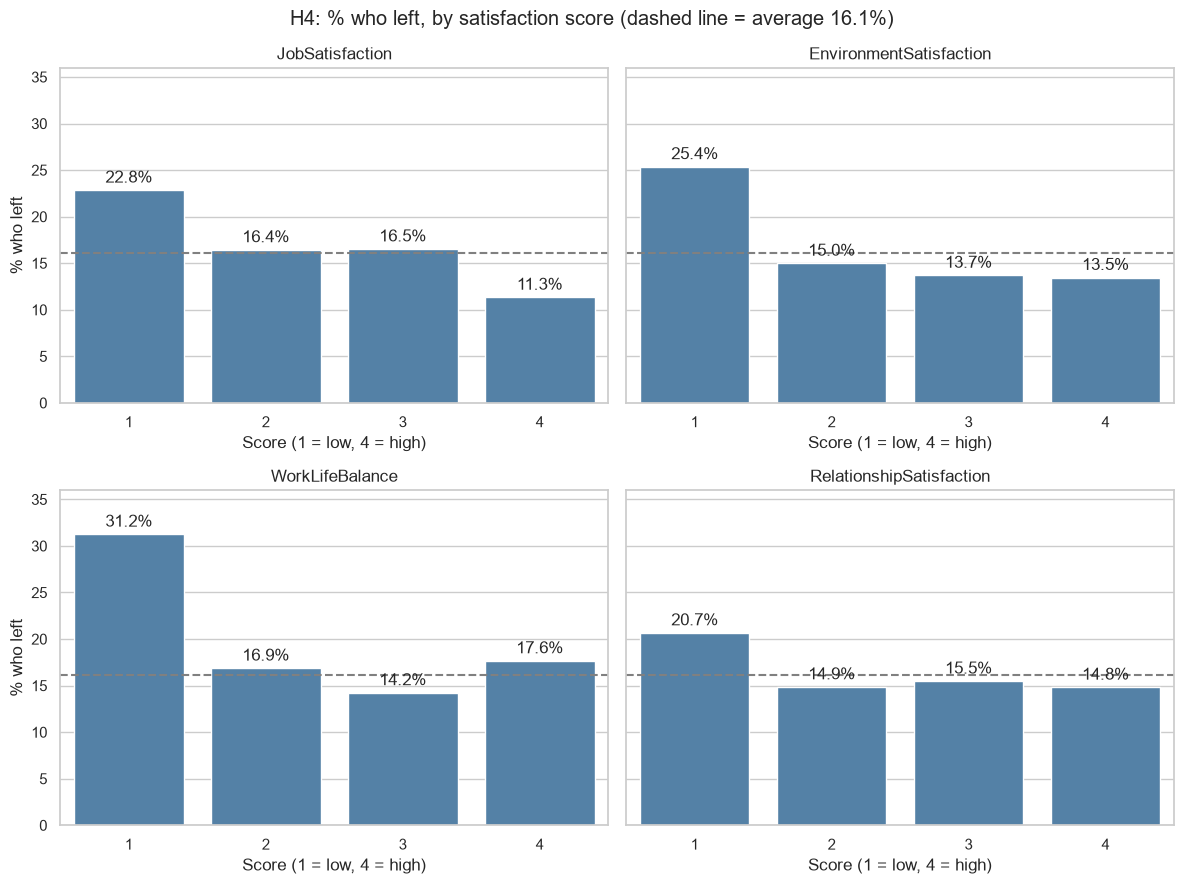

JobSatisfaction: real difference, very unlikely to be chance (p = 0.00056)
EnvironmentSatisfaction: real difference, very unlikely to be chance (p = 5.1e-05)
WorkLifeBalance: real difference, very unlikely to be chance (p = 0.00097)
RelationshipSatisfaction: no real difference, could easily be chance (p = 0.15)


In [23]:
scores = ["JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "RelationshipSatisfaction"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)

for ax, column in zip(axes.flat, scores):
    rates = eda_df.groupby(column)["Attrition"].apply(lambda s: (s == "Yes").mean() * 100)
    sns.barplot(x=rates.index.astype(str), y=rates.values, color="steelblue", ax=ax)
    ax.axhline(overall_rate, ls="--", color="grey")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
    ax.set_ylim(0, 36)
    ax.set_title(column)
    ax.set_xlabel("Score (1 = low, 4 = high)")
    ax.set_ylabel("% who left")

fig.suptitle("H4: % who left, by satisfaction score (dashed line = average 16.1%)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/simple_h4_satisfaction.png", dpi=300, bbox_inches="tight")
plt.show()

for column in scores:
    is_it_chance(column)

**Supported.** Unhappy employees leave more, mostly those who give the
**lowest score (1)**. Poor work-life balance stands out: **31%** of people who scored it
1 left. How people get on with colleagues (relationship satisfaction) makes no real
difference.

**For HR:** follow up quickly with anyone who gives a score of 1 in a staff survey.

### 4.6 H5: Do people who travel a lot leave more?

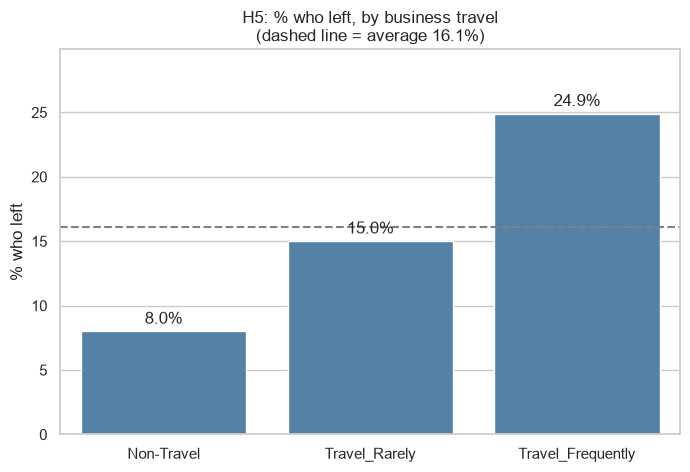

BusinessTravel: real difference, very unlikely to be chance (p = 5.6e-06)


In [24]:
rate_chart(
    "BusinessTravel",
    title="H5: % who left, by business travel",
    filename="simple_h5_travel.png",
    order=['Non-Travel', 'Travel_Rarely', 'Travel_Frequently']
)

is_it_chance("BusinessTravel")

**Supported.** The more people travel, the more they leave: **8%** for no travel,
**15%** for rare travel and **25%** for frequent travel, about 3 times more than
non-travellers.

**For HR:** share travel more evenly and give frequent travellers time to recover.

### 4.7 H6: Does job role make a difference?

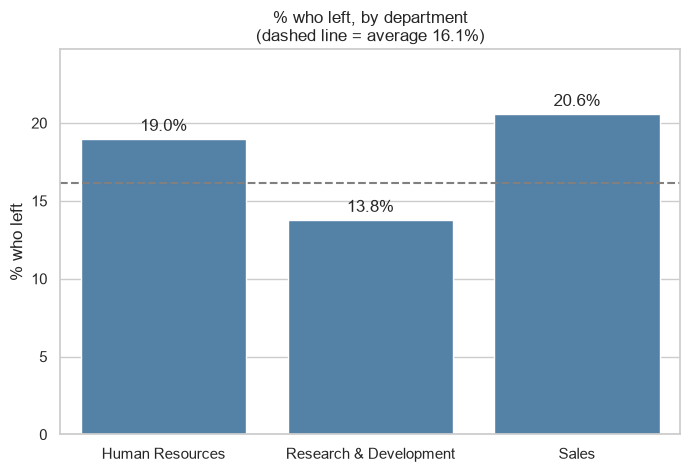

Department: real difference, very unlikely to be chance (p = 0.0045)


In [25]:
rate_chart(
    "Department",
    title="% who left, by department",
    filename="simple_h6_department.png"
)

is_it_chance("Department")

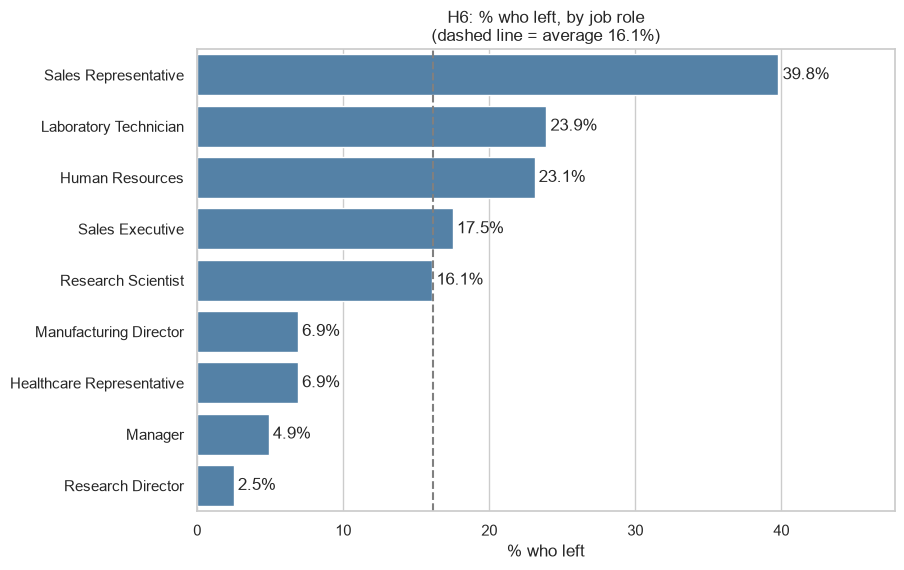

JobRole: real difference, very unlikely to be chance (p = 2.8e-15)


In [26]:
role_order = (
    eda_df.groupby("JobRole")["Attrition"]
    .apply(lambda s: (s == "Yes").mean())
    .sort_values(ascending=False)
    .index.tolist()
)

rate_chart("JobRole", title="H6: % who left, by job role", filename="simple_h6_role.png",
           order=role_order, horizontal=True)

is_it_chance("JobRole")

**Supported.** Job role makes a big difference: **4 in 10 Sales Representatives**
left (39.8%), against only 2.5% of Research Directors. Laboratory Technicians (23.9%)
are also high. Departments differ much less (14–21%), so the **role** matters more than
the department.

**For HR:** focus retention on Sales Representatives and Laboratory Technicians,
mostly entry-level jobs.

### 4.8 H7: Do gender and education make a difference? (control)

We expect **no** difference here. If our method flagged everything, this check would
catch it.

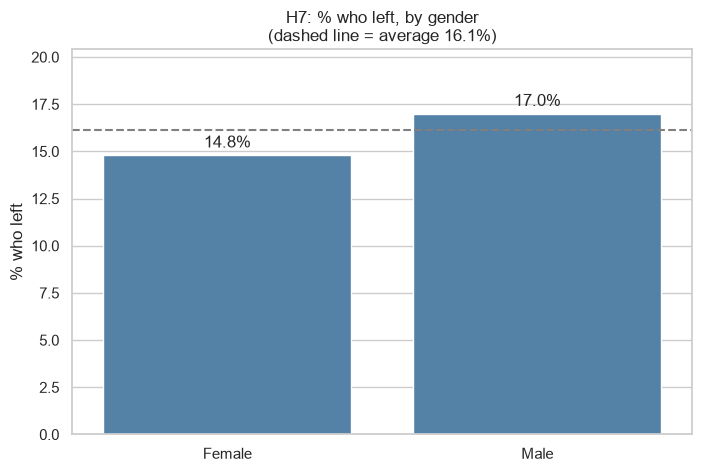

Gender: no real difference, could easily be chance (p = 0.29)


In [27]:
rate_chart(
    "Gender",
    title="H7: % who left, by gender",
    filename="simple_h7_gender.png"
)

is_it_chance("Gender")

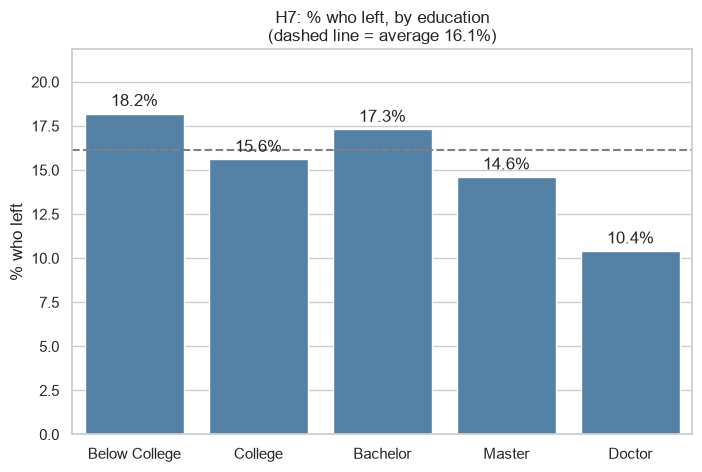

Education level: no real difference, could easily be chance (p = 0.55)


In [28]:
eda_df["Education level"] = eda_df["Education"].map(
    {1: "Below College", 2: "College", 3: "Bachelor", 4: "Master", 5: "Doctor"}
)

rate_chart("Education level", title="H7: % who left, by education",
           filename="simple_h7_education.png",
           order=["Below College", "College", "Bachelor", "Master", "Doctor"])

is_it_chance("Education level")

**Supported, as expected.** Men and women leave at similar rates (17.0% and
14.8%), and education makes no real difference.

**For HR:** gender and education are not useful for deciding where to focus retention.

### 4.9 Which numbers are most linked to leaving?

A bar to the left means "the higher this number, the **less** people leave";
a bar to the right means "the higher, the **more** they leave". Longer bar = stronger link.

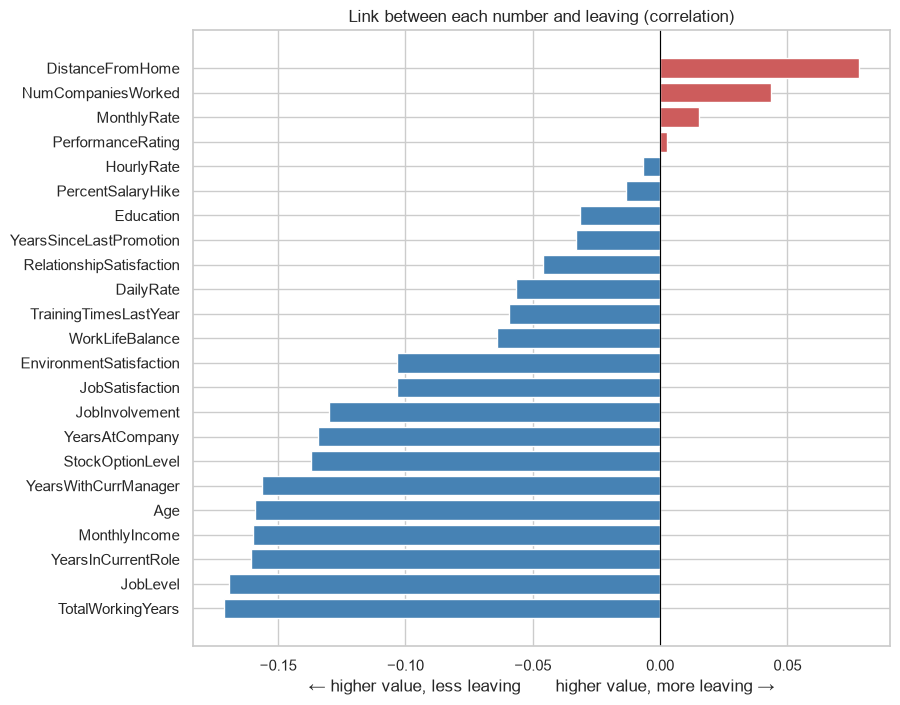

In [29]:
numbers = df_clean.select_dtypes(include="number")

links = numbers.corrwith((df_clean["Attrition"] == "Yes").astype(int)).sort_values()

plt.figure(figsize=(9, 8))

plt.barh(links.index, links.values, color=["indianred" if v > 0 else "steelblue" for v in links.values])

plt.axvline(0, color="black", lw=0.8)

plt.title("Link between each number and leaving (correlation)")
plt.xlabel("← higher value, less leaving       higher value, more leaving →")

plt.savefig(f"{FIG_DIR}/simple_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

**What we found:** no single number is strongly linked to leaving. The strongest
links are all about **experience**: people with more working years, a higher job level,
higher pay and older age leave less. This fits H2 and H3.

### 4.10 Summary

| Idea | Result | In one line |
|---|---|---|
| H1 Overtime | **Supported** | Overtime workers leave 3 times more |
| H2 Pay | **Partly supported** | Lower pay mostly means "junior"; pay matters only at entry level |
| H3 New and young staff | **Supported** | First 2 years and age 18–25 are the riskiest |
| H4 Satisfaction | **Supported** | A score of 1, especially for work-life balance, is a warning sign |
| H5 Travel | **Supported** | Frequent travellers leave 3 times more |
| H6 Job role | **Supported** | Sales Representatives: 4 in 10 left |
| H7 Gender and education | **Supported** (no effect) | No real difference |

**The story in three points:**

1. **Early career:** new, young, entry-level staff leave most.
2. **Workload:** overtime and frequent travel go with 3 times more leaving.
3. **Unhappiness:** the lowest satisfaction scores are a warning sign.